In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import tensorflow as tf
import numpy as np
import os

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import (
    Conv2D, BatchNormalization, Activation,
    Input, GlobalAveragePooling2D,
    Dense, Dropout, Concatenate, AveragePooling2D
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 120
TRAIN_DIR = "/content/drive/MyDrive/augmentation12classesrice disease"
VAL_DIR   = "/content/drive/MyDrive/RiceLeafDisease12classes/validation"

In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    zoom_range=0.25,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.7,1.3]
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

val_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# ✅ IMPORTANT (Fix your error here)
class_names = list(train_generator.class_indices.keys())
NUM_CLASSES = len(class_names)

print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

Found 11997 images belonging to 12 classes.
Found 1413 images belonging to 12 classes.
Classes: ['Hispa', 'Ragged Stunt Virus', 'Sheath Rot', 'Stem Rot', 'Tungro', 'bacterial_leaf_blight', 'brown_spot', 'healthy', 'irrelevant_pics', 'leaf_blast', 'leaf_scald', 'narrow_brown_spot']
Number of classes: 12


In [ ]:
def dense_block(x, growth_rate, num_layers):

    for i in range(num_layers):

        y = BatchNormalization()(x)
        y = Activation("relu")(y)
        y = Conv2D(4 * growth_rate, 1, padding="same")(y)

        y = BatchNormalization()(y)
        y = Activation("relu")(y)
        y = Conv2D(growth_rate, 3, padding="same")(y)

        x = Concatenate()([x, y])   # key idea

    return x

In [ ]:
def transition_block(x, reduction=0.5):

    filters = int(x.shape[-1] * reduction)

    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(filters, 1, padding="same")(x)

    x = AveragePooling2D(2, strides=2)(x)

    return x

In [ ]:
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = Conv2D(64, 7, strides=2, padding="same")(inputs)
x = BatchNormalization()(x)
x = Activation("relu")(x)
x = AveragePooling2D(3, strides=2, padding="same")(x)

# Dense Blocks
x = dense_block(x, growth_rate=32, num_layers=4)
x = transition_block(x)

x = dense_block(x, growth_rate=32, num_layers=6)
x = transition_block(x)

x = dense_block(x, growth_rate=32, num_layers=8)
x = transition_block(x)

x = dense_block(x, growth_rate=32, num_layers=6)

# Head
x = BatchNormalization()(x)
x = Activation("relu")(x)

x = GlobalAveragePooling2D()(x)

x = Dense(512, activation="relu")(x)
x = Dropout(0.5)(x)

outputs = Dense(NUM_CLASSES, activation="softmax")(x)

model = Model(inputs, outputs)

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS
)

Epoch 1/120
375/375 ━━━━━━━━━━━━━━━━━━━━ 3836s 10s/step - accuracy: 0.5284 - loss: 1.6003 - val_accuracy: 0.0467 - val_loss: 3.0259
Epoch 2/120
375/375 ━━━━━━━━━━━━━━━━━━━━ 230s 612ms/step - accuracy: 0.6960 - loss: 1.2233 - val_accuracy: 0.4749 - val_loss: 1.6868
Epoch 3/120
375/375 ━━━━━━━━━━━━━━━━━━━━ 227s 604ms/step - accuracy: 0.7674 - loss: 1.0949 - val_accuracy: 0.6631 - val_loss: 1.5360
Epoch 4/120
375/375 ━━━━━━━━━━━━━━━━━━━━ 226s 601ms/step - accuracy: 0.8091 - loss: 1.0064 - val_accuracy: 0.5131 - val_loss: 1.8307
Epoch 5/120
375/375 ━━━━━━━━━━━━━━━━━━━━ 228s 607ms/step - accuracy: 0.8260 - loss: 0.9561 - val_accuracy: 0.4317 - val_loss: 2.2204
Epoch 6/120
375/375 ━━━━━━━━━━━━━━━━━━━━ 229s 610ms/step - accuracy: 0.8480 - loss: 0.9169 - val_accuracy: 0.5973 - val_loss: 1.5390
Epoch 7/120
375/375 ━━━━━━━━━━━━━━━━━━━━ 235s 626ms/step - accuracy: 0.8673 - loss: 0.8774 - val_accuracy: 0.7551 - val_loss: 1.2293
Epoch 8/120
375/375 ━━━━━━━━━━━━━━━━━━━━ 231s 615ms/step - accuracy: 0

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

pred = model.predict(val_generator)

y_pred = np.argmax(pred, axis=1)
y_true = val_generator.classes

print("Accuracy:", accuracy_score(y_true, y_pred) * 100)

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

45/45 ━━━━━━━━━━━━━━━━━━━━ 13s 279ms/step
Accuracy: 98.30148619957538

Classification Report:

                       precision    recall  f1-score   support

                Hispa       0.99      1.00      0.99        88
   Ragged Stunt Virus       1.00      1.00      1.00        88
           Sheath Rot       0.99      1.00      0.99        81
             Stem Rot       1.00      1.00      1.00        88
               Tungro       1.00      1.00      1.00        88
bacterial_leaf_blight       0.98      0.99      0.98        88
           brown_spot       0.85      0.94      0.89        88
              healthy       1.00      0.97      0.98        88
      irrelevant_pics       1.00      1.00      1.00       452
           leaf_blast       0.95      0.83      0.88        88
           leaf_scald       1.00      1.00      1.00        88
    narrow_brown_spot       0.99      1.00      0.99        88

             accuracy                           0.98      1413
            macro avg

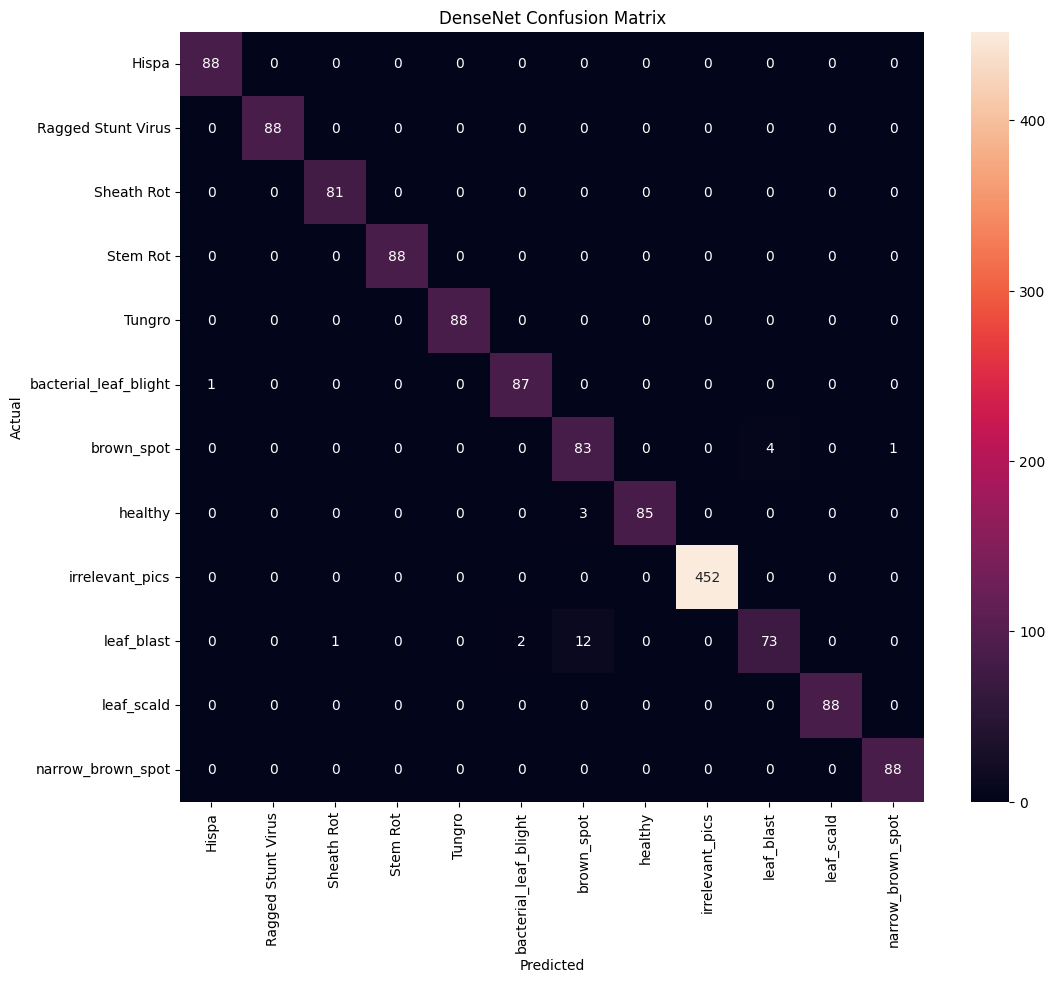

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("DenseNet Confusion Matrix")
plt.show()

In [ ]:
model.save("/content/drive/MyDrive/final_densenet_model.h5")

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("/content/drive/MyDrive/final_densenet_model.h5")

print("✅ Model Loaded Successfully")

✅ Model Loaded Successfully


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_gen = ImageDataGenerator(rescale=1./255)

train_generator = train_gen.flow_from_directory(
    "/content/drive/MyDrive/augmentation12classesrice disease",
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical"
)

class_names = list(train_generator.class_indices.keys())

print("Classes:", class_names)

Found 11997 images belonging to 12 classes.
Classes: ['Hispa', 'Ragged Stunt Virus', 'Sheath Rot', 'Stem Rot', 'Tungro', 'bacterial_leaf_blight', 'brown_spot', 'healthy', 'irrelevant_pics', 'leaf_blast', 'leaf_scald', 'narrow_brown_spot']


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving sheath rot.jpeg to sheath rot.jpeg


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


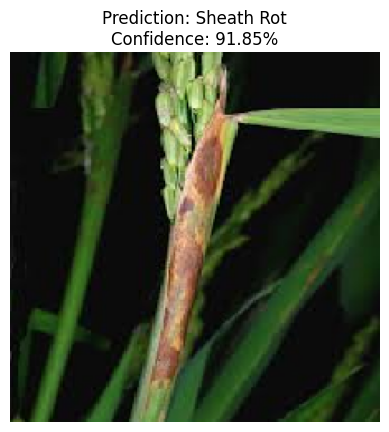

Predicted Class: Sheath Rot
Confidence: 91.85%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

for img_name in uploaded.keys():

    img = image.load_img(img_name, target_size=(224,224))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array)

    predicted_class = class_names[np.argmax(prediction)]
    confidence = np.max(prediction) * 100

    plt.imshow(img)
    plt.title(f"Prediction: {predicted_class}\nConfidence: {confidence:.2f}%")
    plt.axis("off")
    plt.show()

    print("Predicted Class:", predicted_class)
    print(f"Confidence: {confidence:.2f}%")